# AeroMind - Energy Consumption Model

**Module:** AI-based energy estimation (advisory cost estimator inside task allocation)
**Project:** AeroMind - simulation-based multi-drone mission command and coordination platform

## 1. Problem statement

A drone that accepts a task must be able to *finish* it and *return home* with a safety reserve.
Whether it can depends on how much battery each flight leg consumes, and that depends on
distance, climb, payload, wind, the drone's battery health, cruise speed and airframe.

A naive allocator assigns tasks by **straight-line distance only**. It cannot see that a headwind leg
or a heavy-payload leg on a small quadcopter costs far more energy than its distance suggests.

**Goal:** learn `energy_pct = f(leg features)` with a regression model and use it as the cost
function of the Hungarian task-allocation algorithm. The model is *advisory*: a deterministic
distance-based fallback always exists (`strategy=baseline`), and the model can be replaced behind the
`EnergyEstimator` interface without touching the allocator.

**Regression task.** Target: `energy_pct` - percentage of battery consumed by one flight leg.

In [1]:
import sys, json
sys.path.insert(0, "..")
import warnings; warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, KFold, cross_validate
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

from ai.energy_model.features import FEATURE_COLUMNS, TARGET
from ai.energy_model.train import build_pipelines, feature_importance
from ai.energy_model.generate_dataset import SEED

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110

## 2. Dataset

Real multi-drone flight logs with payload, wind and battery-health labels are not available for
this project, so the dataset is **synthetic but physically motivated** (`ai/energy_model/generate_dataset.py`,
seed = 42, 20,000 flight legs). The target follows a documented formula:

* a base cost per metre that depends on the airframe (`quad_small`, `quad_medium`, `hex_heavy`),
* a payload multiplier (small drones suffer more per kg),
* a climb penalty (with a small credit for descent),
* a wind term - headwind raises and tailwind reduces consumption,
* a U-shaped speed-efficiency curve (inefficient at very low or very high speed),
* division by battery health, and ~3 % Gaussian noise.

| column | description |
|---|---|
| distance_m | leg distance (50 - 3000 m) |
| altitude_change_m | -60 to +120 m |
| payload_kg | 0 - 2.5 kg |
| wind_speed_ms | 0 - 14 m/s |
| wind_alignment | -1 (headwind) to +1 (tailwind) |
| battery_health | 0.70 - 1.00 |
| drone_type | quad_small / quad_medium / hex_heavy |
| cruise_speed_ms | 5 - 15 m/s |
| **energy_pct** | **target - % battery consumed** |

Because the data is synthetic, the model's accuracy shows that the *pipeline* works; with real logs
the same code would be retrained (`make train`).

In [2]:
df = pd.read_csv("../data/energy_dataset.csv")
print(df.shape)
df.head()

(20000, 9)


,distance_m,altitude_change_m,payload_kg,wind_speed_ms,wind_alignment,battery_health,cruise_speed_ms,drone_type,energy_pct
0,2333.1703,89.1483,1.6198,13.1442,0.2109,0.8618,6.5190,quad_small,45.3671
1,1344.6914,72.0492,0.3228,13.2667,0.4643,0.8992,14.6654,quad_medium,15.8182
2,2582.8639,95.8027,1.6284,7.5041,0.8100,0.8266,7.0658,hex_heavy,22.6168
3,2107.2357,110.5958,1.6135,3.5121,-0.9302,0.8553,11.6447,hex_heavy,25.4391
4,498.3056,41.5516,1.1727,10.3505,-0.4114,0.9676,14.9398,hex_heavy,7.8009


In [3]:
df.describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
distance_m,20000.0,975.720,832.377,50.021,348.308,645.098,1540.896,2999.844
altitude_change_m,20000.0,30.506,51.700,-59.998,-13.968,30.926,75.027,119.991
payload_kg,20000.0,1.246,0.723,0.000,0.620,1.250,1.868,2.500
wind_speed_ms,20000.0,7.016,4.038,0.000,3.525,7.000,10.542,13.999
wind_alignment,20000.0,-0.003,0.576,-1.000,-0.506,-0.007,0.493,1.000
battery_health,20000.0,0.851,0.087,0.700,0.775,0.850,0.927,1.000
cruise_speed_ms,20000.0,9.970,2.897,5.000,7.447,9.923,12.493,14.998
energy_pct,20000.0,15.134,12.267,0.200,6.345,11.094,20.697,88.054


In [4]:
print("missing values:", int(df.isna().sum().sum()))
print(df["drone_type"].value_counts())

missing values: 0
drone_type
hex_heavy      6729
quad_small     6686
quad_medium    6585
Name: count, dtype: int64


### Distributions

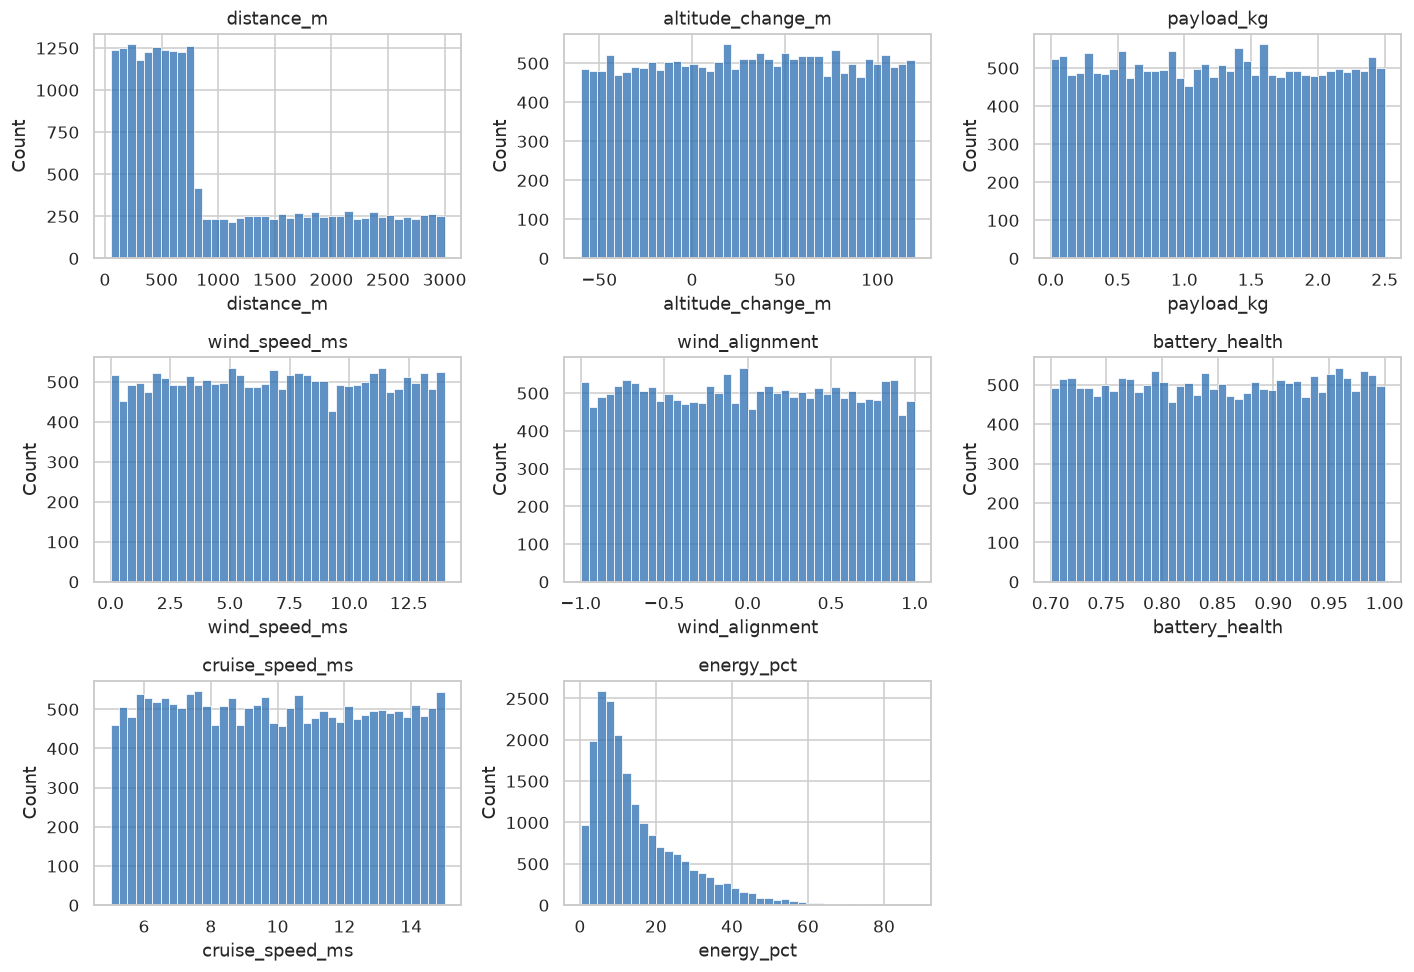

In [5]:
num_cols = [c for c in df.columns if c != "drone_type"]
fig, axes = plt.subplots(3, 3, figsize=(13, 9))
for ax, col in zip(axes.ravel(), num_cols):
    sns.histplot(df[col], bins=40, ax=ax, color="#2b6cb0")
    ax.set_title(col)
axes.ravel()[-1].axis("off")
plt.tight_layout(); plt.show()

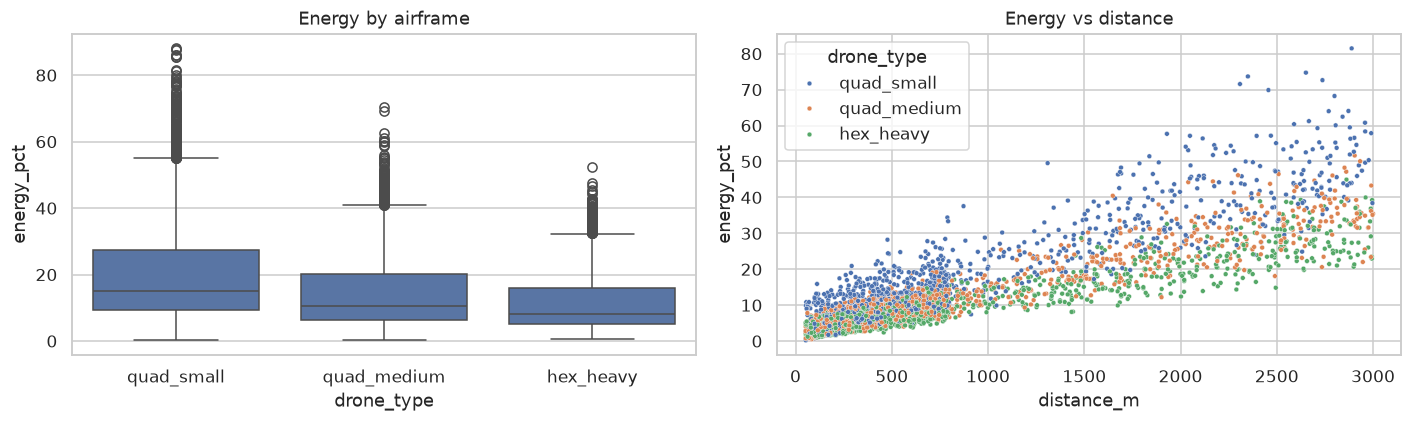

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.boxplot(data=df, x="drone_type", y="energy_pct", ax=axes[0]); axes[0].set_title("Energy by airframe")
sns.scatterplot(data=df.sample(3000, random_state=1), x="distance_m", y="energy_pct",
                hue="drone_type", s=10, ax=axes[1]); axes[1].set_title("Energy vs distance")
plt.tight_layout(); plt.show()

### Correlation heatmap

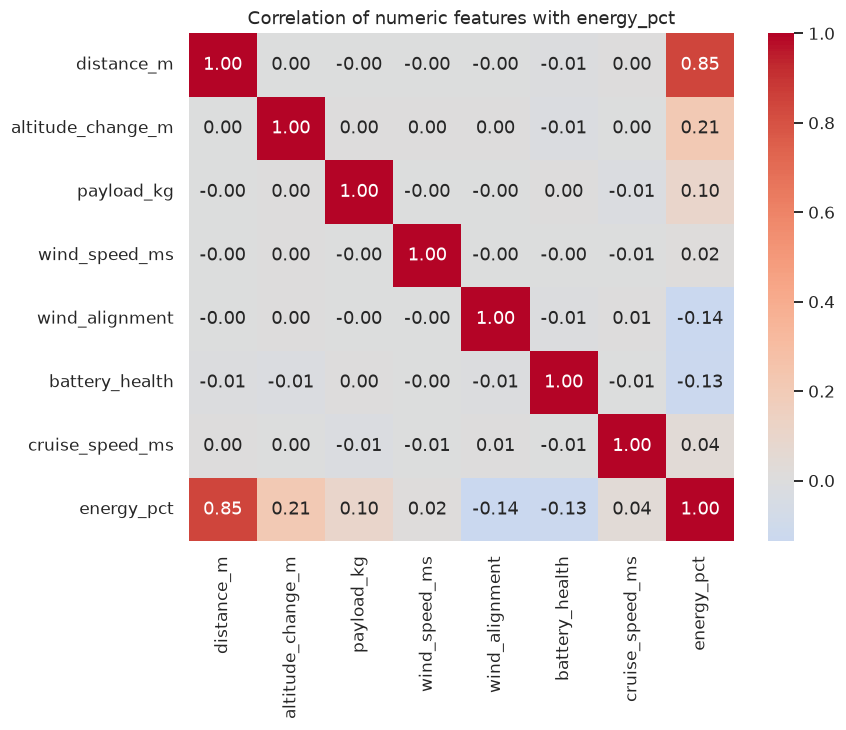

In [7]:
plt.figure(figsize=(8, 6))
sns.heatmap(df[num_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation of numeric features with energy_pct"); plt.show()

Distance dominates, as expected. Altitude change, payload and wind contribute less linearly and
interact with the airframe type - which is why a linear model will struggle and tree ensembles should do better.

## 3. Train / test split

80 % train / 20 % test, fixed seed. `drone_type` is one-hot encoded inside each scikit-learn `Pipeline`
so the saved artifact accepts raw feature rows.

In [8]:
X, y = df[FEATURE_COLUMNS], df[TARGET]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=SEED)
print("train:", X_train.shape, " test:", X_test.shape)

train: (16000, 8)  test: (4000, 8)


## 4. Model comparison

Three regressors are compared: **LinearRegression** (baseline), **RandomForestRegressor** and
**GradientBoostingRegressor**. Each is scored with 5-fold cross-validation on the training split and
then on the held-out test set. The winner is chosen by **lowest cross-validated RMSE** (so the test set is
not used for selection).

In [9]:
kfold = KFold(n_splits=5, shuffle=True, random_state=SEED)
rows, fitted = [], {}
for name, pipe in build_pipelines().items():
    cv = cross_validate(pipe, X_train, y_train, cv=kfold,
                        scoring=("neg_root_mean_squared_error", "neg_mean_absolute_error", "r2"))
    pipe.fit(X_train, y_train)
    pred = pipe.predict(X_test)
    fitted[name] = pipe
    rows.append({
        "model": name,
        "CV RMSE": -cv["test_neg_root_mean_squared_error"].mean(),
        "CV RMSE std": cv["test_neg_root_mean_squared_error"].std(),
        "test MAE": mean_absolute_error(y_test, pred),
        "test RMSE": np.sqrt(mean_squared_error(y_test, pred)),
        "test R2": r2_score(y_test, pred),
    })
results = pd.DataFrame(rows).set_index("model").round(4)
best = results["CV RMSE"].idxmin()
print("best model:", best)
results

best model: GradientBoostingRegressor


,CV RMSE,CV RMSE std,test MAE,test RMSE,test R2
model,,,,,
LinearRegression,3.9428,0.0530,2.7928,4.1136,0.8932
RandomForestRegressor,1.9056,0.0397,1.1028,1.8917,0.9774
GradientBoostingRegressor,1.0771,0.0252,0.6444,1.0433,0.9931


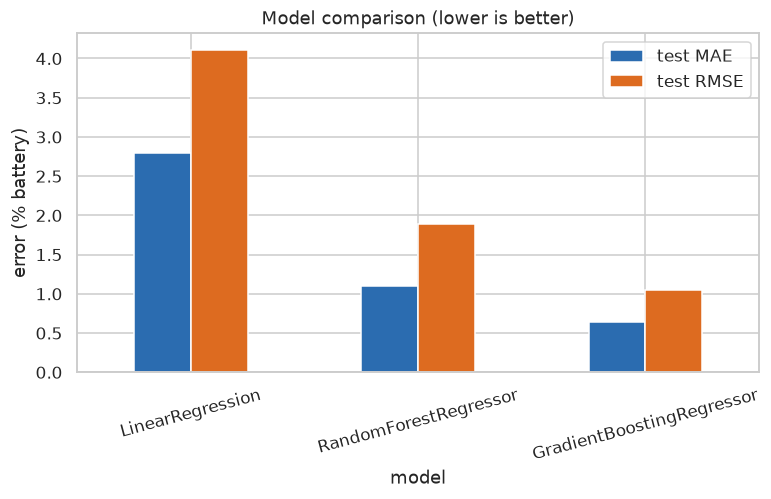

In [10]:
ax = results[["test MAE", "test RMSE"]].plot.bar(figsize=(8, 4), rot=15, color=["#2b6cb0", "#dd6b20"])
ax.set_ylabel("error (% battery)"); ax.set_title("Model comparison (lower is better)"); plt.show()

### Does the saved artifact match this run?

The backend loads `ai/energy_model/artifacts/energy_model.joblib`, written by `make train`.
Its `metrics.json` should agree with the numbers above.

In [11]:
saved = json.load(open("../ai/energy_model/artifacts/metrics.json"))
print("saved best model:", saved["best_model"], "| notebook best:", best)
pd.DataFrame(saved["models"]).T[["mae", "rmse", "r2", "cv_rmse_mean"]]

saved best model: GradientBoostingRegressor | notebook best: GradientBoostingRegressor


,mae,rmse,r2,cv_rmse_mean
LinearRegression,2.7928,4.1136,0.8932,3.9428
RandomForestRegressor,1.1028,1.8917,0.9774,1.9056
GradientBoostingRegressor,0.6444,1.0433,0.9931,1.0771


## 5. Predicted vs actual

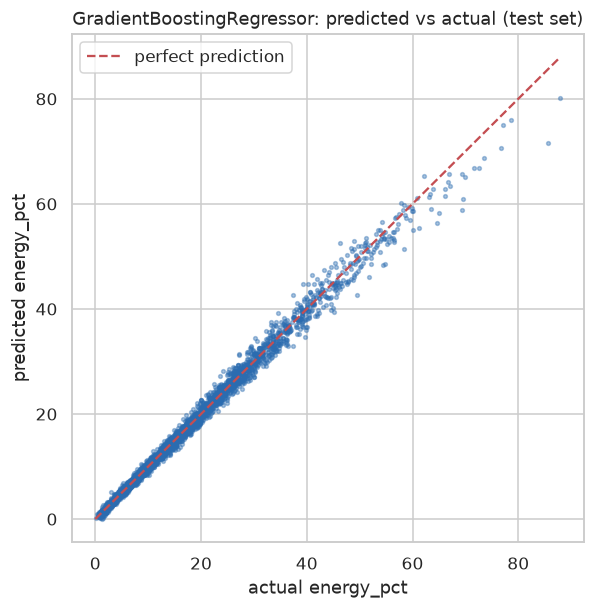

In [12]:
best_pipe = fitted[best]
pred = best_pipe.predict(X_test)
plt.figure(figsize=(6, 6))
plt.scatter(y_test, pred, s=6, alpha=0.4, color="#2b6cb0")
lim = [0, max(y_test.max(), pred.max())]
plt.plot(lim, lim, "r--", label="perfect prediction")
plt.xlabel("actual energy_pct"); plt.ylabel("predicted energy_pct")
plt.title(f"{best}: predicted vs actual (test set)"); plt.legend(); plt.show()

## 6. Residuals

Residual = actual - predicted. A good model has residuals centred on zero with no visible pattern.

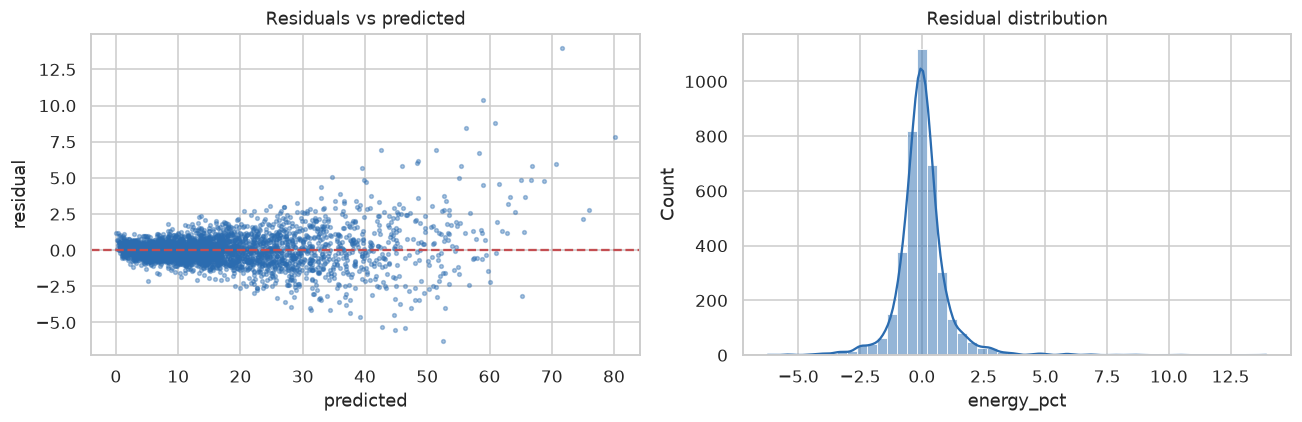

mean residual 0.0195, std 1.0433


In [13]:
resid = y_test - pred
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].scatter(pred, resid, s=6, alpha=0.4, color="#2b6cb0")
axes[0].axhline(0, color="r", ls="--"); axes[0].set_xlabel("predicted"); axes[0].set_ylabel("residual")
axes[0].set_title("Residuals vs predicted")
sns.histplot(resid, bins=50, kde=True, ax=axes[1], color="#2b6cb0"); axes[1].set_title("Residual distribution")
plt.tight_layout(); plt.show()
print(f"mean residual {resid.mean():.4f}, std {resid.std():.4f}")

## 7. Feature importance

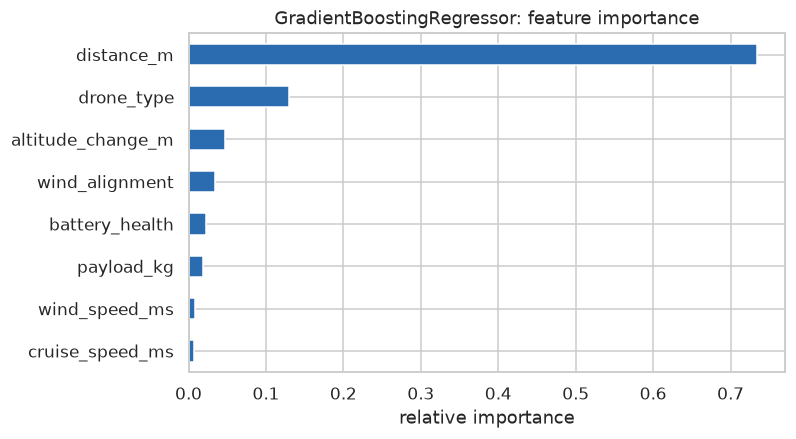

distance_m           0.734
drone_type           0.129
altitude_change_m    0.047
wind_alignment       0.035
battery_health       0.022
payload_kg           0.018
wind_speed_ms        0.009
cruise_speed_ms      0.006
dtype: float64

In [14]:
imp = pd.Series(feature_importance(best_pipe)).sort_values()
imp.plot.barh(figsize=(7, 4), color="#2b6cb0")
plt.xlabel("relative importance"); plt.title(f"{best}: feature importance"); plt.show()
imp.sort_values(ascending=False).round(3)

## 8. Conclusion

* The tree ensembles explain nearly all of the variance in leg energy, while the linear model leaves a
  large error because energy depends on *interactions* (airframe x payload x wind x climb).
* **Distance** is the most important feature, but payload, wind alignment, altitude change and the airframe
  together carry a meaningful share of the signal - information a distance-only allocator throws away.
* In AeroMind this model feeds `ai/allocation.py` as the Hungarian cost matrix, and also as the
  return-to-home energy estimate that enforces the battery reserve. `ai/evaluate_allocation.py`
  quantifies the benefit over the distance-only baseline on 200 random missions.
* **Limitation:** the data is synthetic. The pipeline, interfaces and evaluation are real; swapping in logs
  from PX4/Gazebo flights (the next milestone) only requires regenerating `data/energy_dataset.csv`
  and running `make train`.